# Análise exploratória
Este notebook tem como objetivo realizar a análise exploratória e a validação preliminar dos dados higienizados provenientes da camada de staging (`stg_bank_marketing`) no banco de dados relacional. 

O foco é compreender a distribuição das variáveis, identificar desbalanceamento de classes, detectar padrões em relação à conversão de depósitos a prazo e apontar limitações que influenciarão a fase de modelagem preditiva.

## 1. Configuração do Ambiente e Conexão ao Banco de Dados

In [1]:
# Bibliotecas
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Raiz do projeto ao path
ROOT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT_DIR) not in sys.path:
    sys.path.append(str(ROOT_DIR))

from src.database import get_engine

# Configurações globais de layout
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

engine = get_engine()
df = pd.read_sql("SELECT * FROM stg_bank_marketing", con=engine)
engine.dispose()

In [2]:
# Exibir as primeiras 5 linhas
df.head()

,age,job,marital,education,default_credit,balance,housing,loan,contact,day,month,campaign,pdays,previous_contact,previous,poutcome,target
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,1,NaN,0,0,unknown,0
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,1,NaN,0,0,unknown,0
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,1,NaN,0,0,unknown,0
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,1,NaN,0,0,unknown,0
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,1,NaN,0,0,unknown,0


## 2. Dimensão e Tipos de Dados

In [3]:
print("Dimensão do Dataframe:", df.shape)

Dimensão do Dataframe: (45211, 17)


In [4]:
df.dtypes

age                   int64
job                     str
marital                 str
education               str
default_credit          str
balance               int64
housing                 str
loan                    str
contact                 str
day                   int64
month                   str
campaign              int64
pdays               float64
previous_contact      int64
previous              int64
poutcome                str
target                int64
dtype: object

## 3. Auditoria de Valores Ausentes e Categorias Sentinela

In [5]:
print(df.isna().sum().sort_values(ascending=False).head(10))

pdays             36954
age                   0
job                   0
education             0
marital               0
balance               0
housing               0
loan                  0
default_credit        0
contact               0
dtype: int64


## 4. Estatística Descritiva das Variáveis Numéricas
Análise de medidas de tendência central (média, mediana) e de dispersão (desvio padrão, quartis, mínimo e máximo) para detectar assimetrias, amplitudes de valores e possíveis anomalias em colunas como `age`, `balance` e `campaign`.

In [6]:
df.describe()

,age,balance,day,campaign,pdays,previous_contact,previous,target
count,45211.000000,45211.000000,45211.000000,45211.000000,8257.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,2.763841,224.577692,0.182633,0.580323,0.116985
std,10.618762,3044.765829,8.322476,3.098021,115.344035,0.386369,2.303441,0.321406
min,18.000000,-8019.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000
25%,33.000000,72.000000,8.000000,1.000000,133.000000,0.000000,0.000000,0.000000
50%,39.000000,448.000000,16.000000,2.000000,194.000000,0.000000,0.000000,0.000000
75%,48.000000,1428.000000,21.000000,3.000000,327.000000,0.000000,0.000000,0.000000
max,95.000000,102127.000000,31.000000,63.000000,871.000000,1.000000,275.000000,1.000000


## 5. Distribuição das Variáveis Contínuas

Visualização da densidade e da frequência das variáveis numéricas contínuas por meio de histogramas e curvas KDE. 

* Variáveis com caudas longas e forte assimetria à direita (como `balance` e `previous`) são exibidas em escala logarítmica para permitir melhor leitura dos dados.

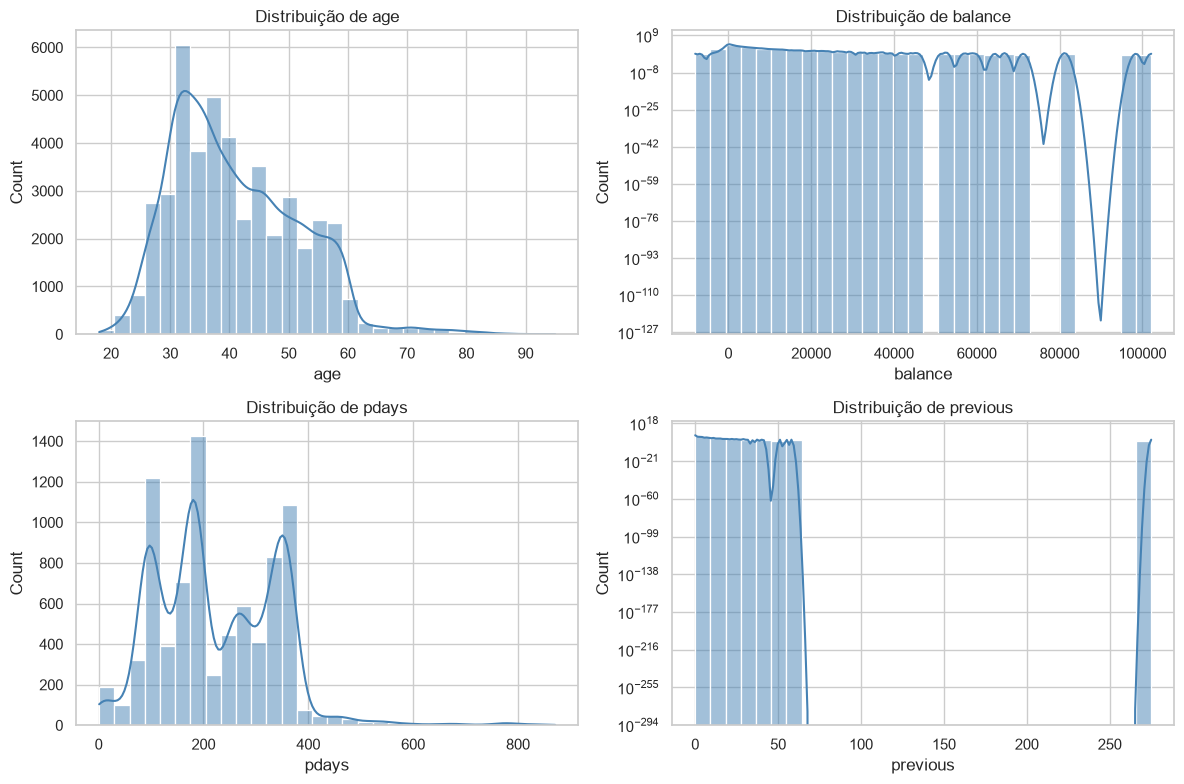

In [7]:
# Histograma para variáveis numéricas
colunas_continuas = ["age", "balance", "pdays", "previous"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

for i, col in enumerate(colunas_continuas):
    sns.histplot(data=df, x=col, kde=True, ax=axes[i], color="steelblue", bins=30)
    axes[i].set_title(f"Distribuição de {col}")
    if col in ["balance", "previous"]:
        axes[i].set_yscale("log")  # Escala logarítmica para variáveis com cauda longa

plt.tight_layout()
plt.show()


## 6. Distribuição da Variável-Alvo (`target`) e Desbalanceamento

Avaliação da proporção da classe positiva (`target = 1`, clientes que aceitaram a oferta) em relação à classe negativa (`target = 0`). 

* A taxa geral de conversão da base é de aproximadamente **11,7%**, caracterizando um cenário clássico de **desbalanceamento de classes**, o que exigirá métricas adequadas (como PR-AUC e Lift) e ajuste de pesos na etapa de modelagem.


Distribuição do target:


target
0    0.883
1    0.117
Name: proportion, dtype: float64

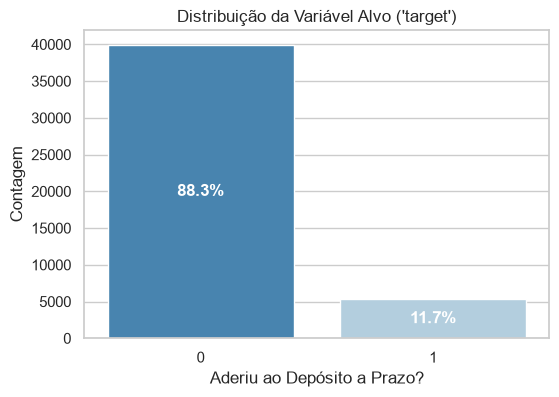

In [8]:
print("\nDistribuição do target:")
display(df["target"].value_counts(normalize=True).round(3))

# Gráfico de barras para a variável target
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df, x='target', hue='target', palette='Blues_r', legend=False)

# Adiciona a porcentagem no topo de cada barra
total = len(df)
for p in ax.patches:
    pct = f"{100 * p.get_height() / total:.1f}%"
    ax.annotate(pct, (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                ha='center', va='center', color='white', fontweight='bold')

plt.title("Distribuição da Variável Alvo ('target')")
plt.xlabel("Aderiu ao Depósito a Prazo?")
plt.ylabel("Contagem")
plt.show()

## 7. Análise Bivariada: Taxa de Aceitação por Atributos Categóricos

Investigação da taxa de conversão cruzada com as principais características do cliente e da abordagem comercial:

* **Ocupação (`job`):** Segmentos como estudantes e aposentados costumam registrar taxas de conversão substancialmente acima da média geral da base.
* **Empréstimo Imobiliário (`housing`):** Clientes com comprometimento de renda em crédito habitacional tendem a apresentar menor propensão a novos investimentos a prazo.
* **Desfecho Anterior (`poutcome`):** Clientes com histórico de contratação prévia (`success`) representam a alavanca com maior potencial relativo de conversão.

In [9]:
# Função para plotar taxa de aceite
def plotar_taxa_aceite(dataframe, coluna, titulo, exibir_tabela=True, horizontal=False):
    """
    Agrupa o dataframe pela coluna informada, calcula a contagem e a taxa média de conversão (target),
    exibe o resumo em tabela (opcional) e plota um gráfico de barras com anotações percentuais.
    """
    # 1. Agrupamento e cálculo das taxas
    resumo = (
        dataframe.groupby(coluna, dropna=False)["target"]
        .agg(["count", "mean"])
        .sort_values("mean", ascending=False)
        .reset_index()
    )
    resumo["taxa_pct"] = resumo["mean"] * 100

    if exibir_tabela:
        print(f"--- Resumo: {titulo} ---")
        display(resumo)
        print("\n" + "="*50 + "\n")

    # 2. Configuração do Gráfico
    plt.figure(figsize=(10, 5))
    
    if horizontal:
        ax = sns.barplot(
            data=resumo, 
            x="taxa_pct", 
            y=coluna, 
            hue=coluna, 
            palette="Blues_r", 
            legend=False
        )
        for p in ax.patches:
            width = p.get_width()
            if width > 0:
                ax.annotate(
                    f"{width:.1f}%", 
                    (width / 2, p.get_y() + p.get_height() / 2.),
                    ha="center", va="center", color="white", fontweight="bold"
                )
        plt.xlabel("Taxa de Contratação (%)")
        plt.ylabel(coluna)
    else:
        ax = sns.barplot(
            data=resumo, 
            x=coluna, 
            y="taxa_pct", 
            hue=coluna, 
            palette="Blues_r", 
            legend=False
        )
        for p in ax.patches:
            height = p.get_height()
            if height > 0:
                ax.annotate(
                    f"{height:.1f}%", 
                    (p.get_x() + p.get_width() / 2., height / 2),
                    ha="center", va="center", color="white", fontweight="bold"
                )
        plt.ylabel("Taxa de Contratação (%)")
        plt.xlabel(coluna)
        plt.xticks(rotation=45, ha='right')

    plt.title(titulo)
    plt.tight_layout()
    plt.show()

--- Resumo: Taxa de Contratação por Ocupação ---


,job,count,mean,taxa_pct
0,student,938,0.286780,28.678038
1,retired,2264,0.227915,22.791519
2,unemployed,1303,0.155027,15.502686
3,management,9458,0.137556,13.755551
4,admin.,5171,0.122027,12.202669
5,self-employed,1579,0.118429,11.842939
6,unknown,288,0.118056,11.805556
7,technician,7597,0.110570,11.056996
8,services,4154,0.088830,8.883004
9,housemaid,1240,0.087903,8.790323


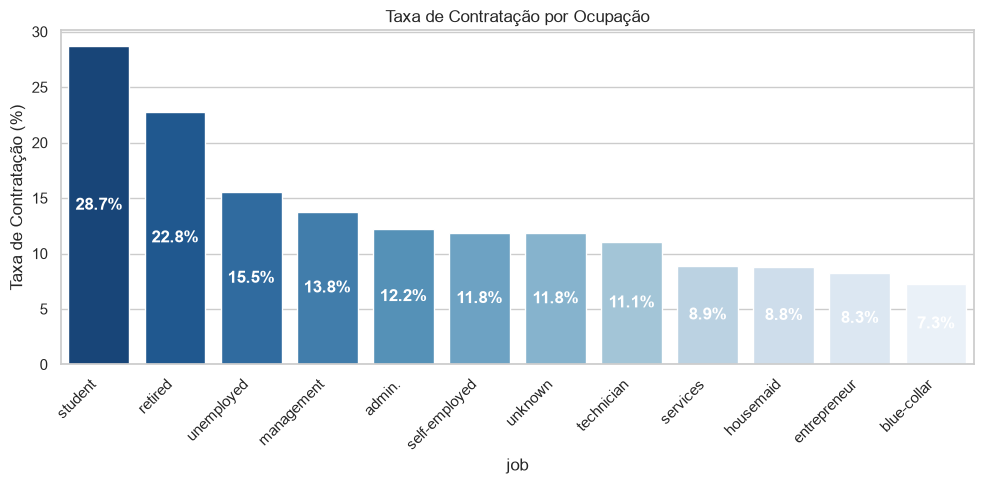

--- Resumo: Taxa de Contratação por Empréstimo Imobiliário ---


,housing,count,mean,taxa_pct
0,no,20081,0.167024,16.702355
1,yes,25130,0.077000,7.699960


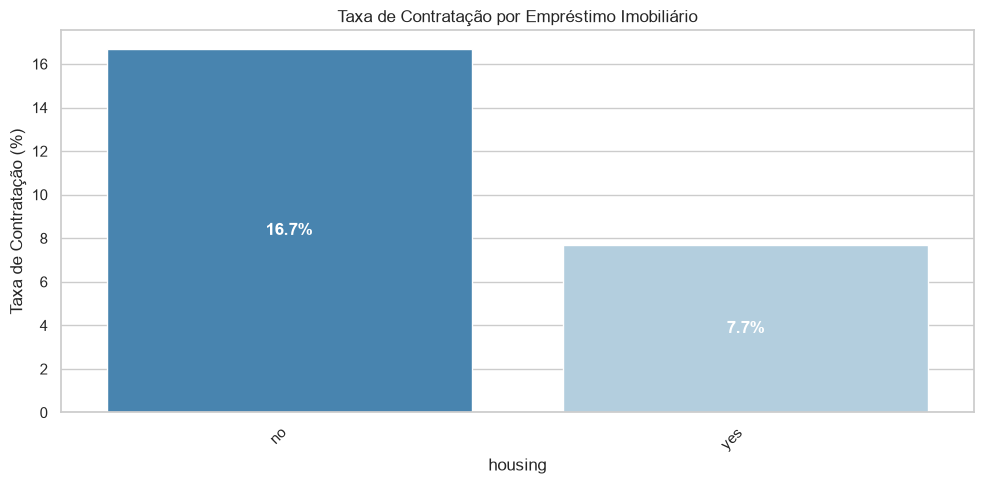

--- Resumo: Taxa de Contratação por Desfecho da Campanha Anterior ---


,poutcome,count,mean,taxa_pct
0,success,1511,0.647253,64.725347
1,other,1840,0.166848,16.684783
2,failure,4901,0.126097,12.609671
3,unknown,36959,0.091615,9.161503


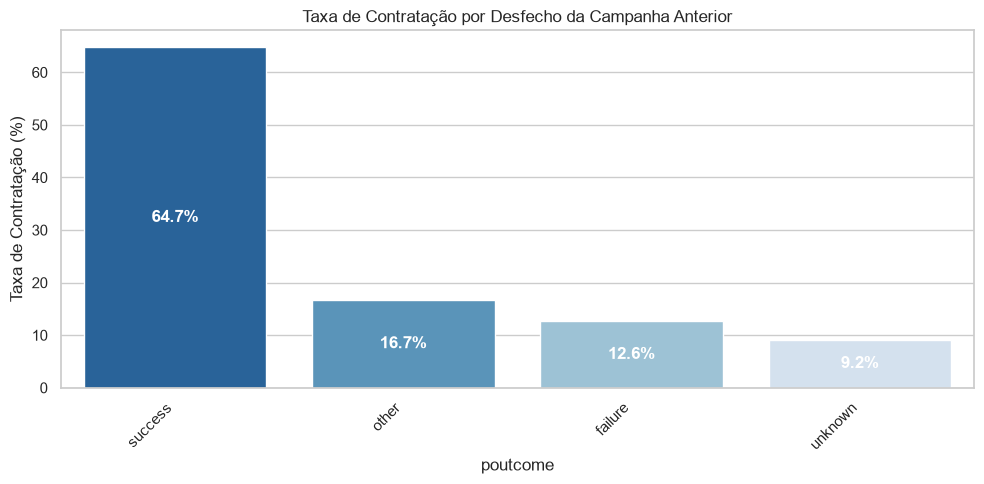

In [10]:
# Taxa de contratação por Ocupação (gráfico vertical com rotação de labels)
plotar_taxa_aceite(df, "job", "Taxa de Contratação por Ocupação")

# Taxa de contratação por Empréstimo Imobiliário
plotar_taxa_aceite(df, "housing", "Taxa de Contratação por Empréstimo Imobiliário")

# Taxa de contratação por Desfecho da Campanha Anterior
plotar_taxa_aceite(df, "poutcome", "Taxa de Contratação por Desfecho da Campanha Anterior")

## 8. Relação entre Saldo Bancário (`balance`), Idade (`age`) e Conversão

Inspeção da dispersão e presença de outliers em `age` e `balance` estratificados pela variável `target`. A utilização de boxplots em escala simétrica (`symlog`) viabiliza a análise de saldos negativos decorrentes de limites de conta ou cheque especial.

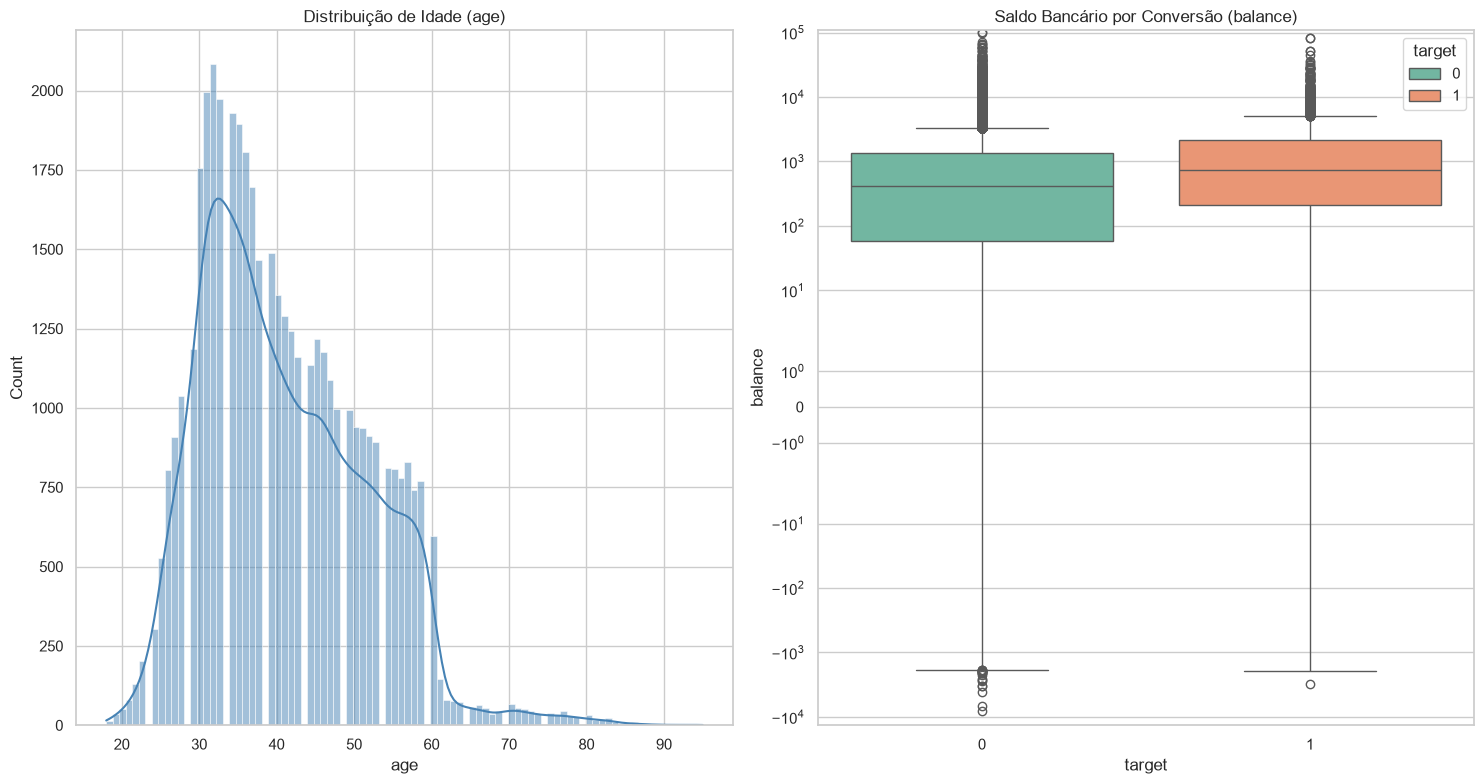

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(15, 8))

# Idade
sns.histplot(data=df, x='age', kde=True, ax=axes[0], color='steelblue')
axes[0].set_title("Distribuição de Idade (age)")

# Saldo bancário (usando escala logarítmica ou limite para lidar com outliers)
sns.boxplot(data=df, x='target', y='balance', hue='target', ax=axes[1], palette='Set2')
axes[1].set_title("Saldo Bancário por Conversão (balance)")
axes[1].set_yscale('symlog')  # Escala simétrica para aceitar saldos negativos

plt.tight_layout()
plt.show()

## 9. Síntese dos Principais Insights
1. **Desbalanceamento:** Cerca de 88,3% dos contatos resultaram em recusa e 11,7% em contratação, evidenciando a necessidade de priorização inteligente via CRM.
2. **Histórico de Relacionamento:** O histórico de campanhas prévias e a estabilidade financeira exercem papel determinante na conversão.
3. **Prevenção de Vazamento de Dados (*Data Leakage*):** Variáveis operacionais conhecidas apenas durante ou após o contato (como `duration`) devem ser excluídas do treinamento nos modelos de propensão de pré-campanha.

## 10. Matriz de Correlação
Para avaliar a multicolinearidade e investigar relações lineares diretas entre as variáveis quantitativas da base e a variável-alvo (`target`), construiu-se a matriz de correlação de Pearson.

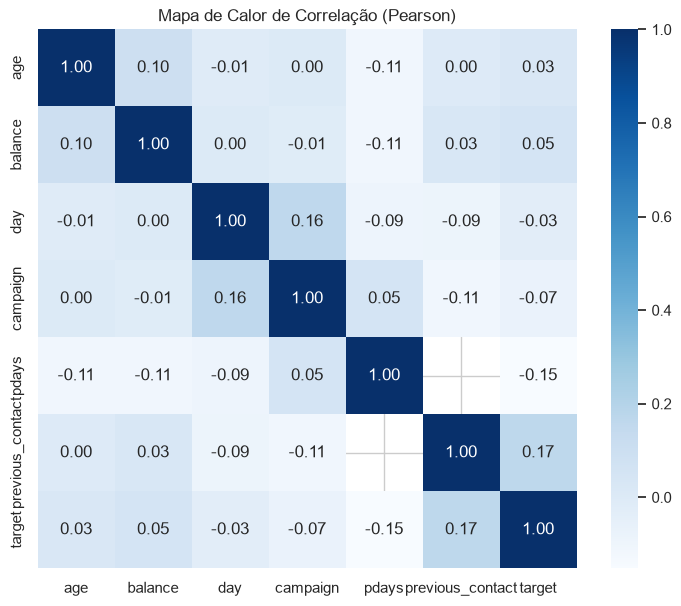

In [13]:
colunas_num = ['age', 'balance', 'day', 'campaign', 'pdays', 'previous_contact', 'target']
colunas_cat = ['poutcome', 'target']

# Mapa de calor de correlação
df[colunas_num].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(df[colunas_num].corr(), annot=True, fmt=".2f", cmap='Blues', cbar=True, square=True)
plt.title("Mapa de Calor de Correlação (Pearson)")
plt.show()

A matriz de Corelação apresentou: 
* Ausência de Forte Correlação Linear com o Alvo (target) - os coeficientes de correlação entre o target e as variáveis numéricas (age, balance, day, campaign, pdays, previous_contact) são próximos de zero (variando entre -0.15 e 0.17).

    * Demonstrando que não existem relações lineares diretas e isoladas entre essas variáveis contínuas e a decisão do cliente de aceitar ou não o depósito a prazo. 

* Correlações Internas Fracas entre as Features - a grande maioria dos cruzamentos entre as variáveis preditoras apresenta valores próximos de 0.10 ou menores 
    * Indicativo de baixa multicolinearidade entre os preditores numéricos lineares.